In [1]:
#Task 1
# Hazır GPT-2'yi incele. Hugging Face'ten GPT-2 (124M) ağırlıklarını
# yükle. Her ağırlığın adını ve boyutunu yazdır, toplam parametre sayısını
# hesapla. Pozisyon embedding'lerini (wpe) çiz: ne görüyorsun, kendi
# cümlelerinle yaz. (0:03:39 - 0:13:47)

In [2]:
from transformers import GPT2LMHeadModel

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
model_hf = GPT2LMHeadModel.from_pretrained("gpt2") #124M version
sd_hf = model_hf.state_dict()

for k, v in sd_hf.items():
    print(k, v.shape)

Loading weights: 100%|██████████████████████| 148/148 [00:00<00:00, 8172.37it/s]

transformer.wte.weight torch.Size([50257, 768])
transformer.wpe.weight torch.Size([1024, 768])
transformer.h.0.ln_1.weight torch.Size([768])
transformer.h.0.ln_1.bias torch.Size([768])
transformer.h.0.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.0.attn.c_attn.bias torch.Size([2304])
transformer.h.0.attn.c_proj.weight torch.Size([768, 768])
transformer.h.0.attn.c_proj.bias torch.Size([768])
transformer.h.0.ln_2.weight torch.Size([768])
transformer.h.0.ln_2.bias torch.Size([768])
transformer.h.0.mlp.c_fc.weight torch.Size([768, 3072])
transformer.h.0.mlp.c_fc.bias torch.Size([3072])
transformer.h.0.mlp.c_proj.weight torch.Size([3072, 768])
transformer.h.0.mlp.c_proj.bias torch.Size([768])
transformer.h.1.ln_1.weight torch.Size([768])
transformer.h.1.ln_1.bias torch.Size([768])
transformer.h.1.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.1.attn.c_attn.bias torch.Size([2304])
transformer.h.1.attn.c_proj.weight torch.Size([768, 768])
transformer.h.1.attn.c_proj.bias 

In [4]:
from transformers import pipeline, set_seed
generator = pipeline("text-generation", model = "gpt2")
set_seed(42)
generator("Hello, I'm a language model,", max_length=30, num_return_sequences=5)   
                     

Loading weights: 100%|█████████████████████| 148/148 [00:00<00:00, 13119.39it/s]
[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to s

[{'generated_text': 'Hello, I\'m a language model, so I\'m able to take ideas and build them from there.\n\nThe problem is, you can\'t say, "I\'m going to use this model with a bunch of different languages but I want to use Java." Instead, you have to say, "I want to use this model with some of the other languages I\'ve used. I want to use Java with some of the other languages I\'ve used." And then one of the things I think people should be able to do is to try to build a language model that gives people the ideas and the understanding to build the language model for them. That\'s what I call the "real world."\n\nHow long do you think it takes to get a language model that\'s working?\n\nIt\'s not that hard. The challenge is, when you\'re building a language model, it\'s going to take a lot of time. It\'s going to take a lot of time to build. It\'s going to take a lot of time to build. That\'s what it takes to build a language model.\n\nThe challenge is, when you\'re building a language

In [5]:
sd_hf["transformer.wpe.weight"].view(-1)[:20]

tensor([-0.0188, -0.1974,  0.0040,  0.0113,  0.0638, -0.1050,  0.0369, -0.1680,
        -0.0491, -0.0565, -0.0025,  0.0135, -0.0042,  0.0151,  0.0166, -0.1381,
        -0.0063, -0.0461,  0.0267, -0.2042])

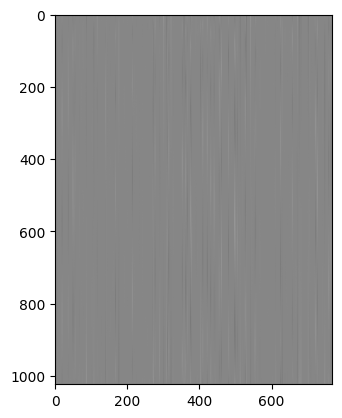

In [6]:
import matplotlib.pyplot as plt
plt.imshow(sd_hf["transformer.wpe.weight"],cmap="gray")

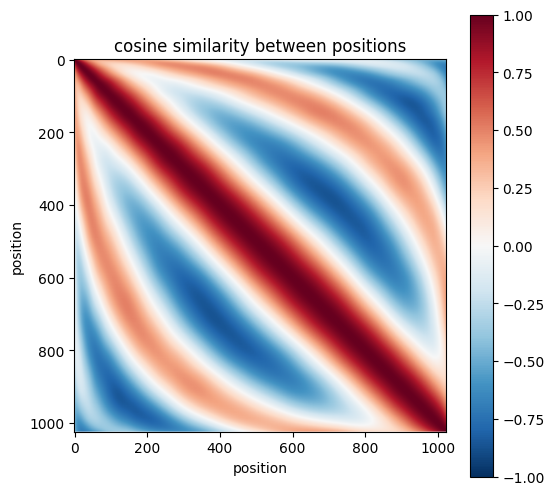

In [7]:
wpe = sd_hf["transformer.wpe.weight"]
wpe_unit = wpe / wpe.norm(dim=1, keepdim=True)
sim = wpe_unit @ wpe_unit.T

plt.figure(figsize=(6, 6))
plt.imshow(sim, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar()
plt.xlabel("position")
plt.ylabel("position")
plt.title("cosine similarity between positions")
plt.show()

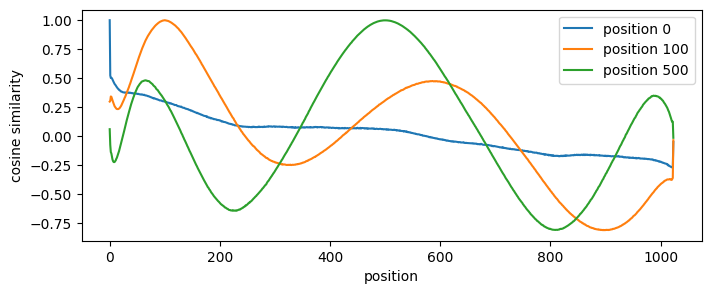

In [8]:
plt.figure(figsize=(8, 3))
for i in [0, 100, 500]:
    plt.plot(sim[i], label=f"position {i}")
plt.xlabel("position")
plt.ylabel("cosine similarity")
plt.legend()
plt.show()

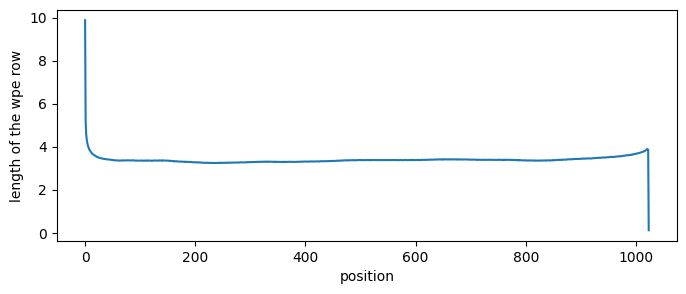

In [9]:
plt.figure(figsize=(8, 3))
plt.plot(wpe.norm(dim=1))
plt.xlabel("position")
plt.ylabel("length of the wpe row")
plt.show()

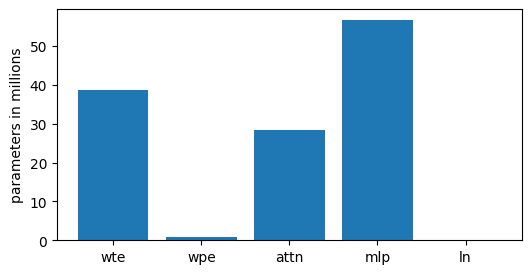

 There are 124439808 parameters in gpt2


In [15]:
counts = {"wte": 0, "wpe": 0, "attn": 0, "mlp": 0, "ln": 0}
for k, v in model_hf.named_parameters():
    if "wte" in k:
        counts["wte"] += v.numel()
    elif "wpe" in k:
        counts["wpe"] += v.numel()
    elif ".attn." in k:
        counts["attn"] += v.numel()
    elif ".mlp." in k:
        counts["mlp"] += v.numel()
    else:
        counts["ln"] += v.numel()

plt.figure(figsize=(6, 3))
plt.bar(counts.keys(), [c / 1e6 for c in counts.values()])
plt.ylabel("parameters in millions")
plt.show()
print(f' There are {sum(p.numel() for p in model_hf.parameters())} parameters in gpt2')